In [ ]:
%pip install numpy 
%pip install pandas
%pip install statsmodels
%pip install matplotlib
%pip install seaborn
%pip install plotly

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly as px
import statsmodels.api as sm
from statsmodels.tsa.stattools import bds
from statsmodels.stats.diagnostic import linear_reset
from scipy import stats
from statsmodels.stats.diagnostic import het_arch
import warnings

In [15]:
warnings.filterwarnings("ignore", category=FutureWarning, module="statsmodels")


In [16]:
df = pd.read_csv("data.csv")

mete_col = ['Diurnal temperature range (°C)', 'Mean temperature (°C)', 'Mean humidity (%)', 'Solar radiation (MJ/m²)', 'Air pressure (hPa)', 'Dew point temperature (°C)', 'Wind speed (km/h)', 'Mean UV']
flu_col = ["H1", "H3", "B", "AandB"]

---

In [25]:
df

,Year,Week,From,Diurnal temperature range (°C),Mean temperature (°C),Mean humidity (%),Solar radiation (MJ/m²),Air pressure (hPa),Dew point temperature (°C),Wind speed (km/h),Mean UV,H1,H3,B,AandB
0,2013,1,2012-12-30,7.01,13.75,66.62,10.95,1020.62,7.12,11.00,2.00,0,23,1,37
1,2013,2,2013-01-06,6.28,14.80,69.04,12.60,1019.42,8.85,11.25,2.29,0,40,6,76
2,2013,3,2013-01-13,7.19,14.98,69.91,13.50,1021.66,9.12,12.25,2.29,0,29,4,75
3,2013,4,2013-01-20,5.98,18.17,79.32,11.48,1019.14,14.35,10.83,2.14,0,37,9,92
4,2013,5,2013-01-27,7.05,17.66,71.69,14.77,1021.33,12.07,13.22,2.67,0,37,6,104
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
704,2026,26,2026-06-28,5.87,27.98,88.04,17.43,1008.09,25.65,13.56,3.56,214,476,111,812
705,2026,27,2026-07-05,6.09,28.02,87.32,17.35,1005.17,25.44,11.67,3.86,304,483,123,928
706,2026,28,2026-07-12,4.31,27.47,90.27,12.12,1004.22,25.60,10.67,2.56,383,533,124,1069
707,2026,29,2026-07-19,6.32,28.44,84.48,18.33,1006.11,25.27,9.44,3.81,483,567,138,1217


In [29]:
df[mete_col].describe()

,Diurnal temperature range (°C),Mean temperature (°C),Mean humidity (%),Solar radiation (MJ/m²),Air pressure (hPa),Dew point temperature (°C),Wind speed (km/h),Mean UV
count,709.000000,709.000000,709.000000,709.000000,709.000000,709.000000,709.000000,709.000000
mean,5.780635,23.182426,79.616178,14.298392,1012.837024,19.089210,12.463836,2.804626
std,1.242457,4.866944,8.708112,4.747681,6.147490,6.034693,2.575496,1.066720
min,2.890000,9.020000,45.900000,3.190000,997.290000,1.540000,6.350000,0.610000
25%,4.930000,18.920000,75.340000,10.920000,1007.840000,14.540000,10.790000,2.000000
50%,5.690000,24.020000,81.620000,14.350000,1012.660000,20.300000,12.250000,2.710000
75%,6.550000,27.730000,85.580000,17.620000,1018.120000,24.770000,13.980000,3.560000
max,9.970000,30.160000,94.550000,26.570000,1026.620000,26.470000,28.230000,6.000000


In [28]:
df[flu_col].describe()

,H1,H3,B,AandB
count,709.000000,709.000000,709.000000,709.000000
mean,105.819464,149.593794,59.245416,321.338505
std,233.296521,283.174331,169.237094,428.734343
min,0.000000,0.000000,0.000000,0.000000
25%,0.000000,9.000000,3.000000,36.000000
50%,18.000000,43.000000,13.000000,147.000000
75%,86.000000,169.000000,50.000000,443.000000
max,1999.000000,2560.000000,1978.000000,2741.000000


In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 709 entries, 0 to 708
Data columns (total 15 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Year                            709 non-null    int64  
 1   Week                            709 non-null    int64  
 2   From                            709 non-null    object 
 3   Diurnal temperature range (°C)  709 non-null    float64
 4   Mean temperature (°C)           709 non-null    float64
 5   Mean humidity (%)               709 non-null    float64
 6   Solar radiation (MJ/m²)         709 non-null    float64
 7   Air pressure (hPa)              709 non-null    float64
 8   Dew point temperature (°C)      709 non-null    float64
 9   Wind speed (km/h)               709 non-null    float64
 10  Mean UV                         709 non-null    float64
 11  H1                              709 non-null    int64  
 12  H3                              709 

---

In [ ]:
# Feature Engineering 
feature_df = df.copy()
feature_df

In [ ]:
feature_df = df

In [ ]:
temp_df_feature = df_feature[["From", "AandB", "Diurnal temperature range (°C)"]]
temp_df_feature

In [ ]:
col_Lag_NoOfWeek

In [ ]:
temp_df_feature["AandB_Lag_1"] = temp_df_feature["AandB"].shift(1)
temp_df_feature["Temp_Lag_1"] = temp_df_feature["Diurnal temperature range (°C)"].shift(1)
temp_df_feature["AandB_Rolling_Mean_4"] = temp_df_feature["AandB"].shift(1).rolling(4).mean()
temp_df_feature["Temp_Rolling_Mean_4"] = temp_df_feature["Diurnal temperature range (°C)"].shift(1).rolling(4).mean()
temp_df_feature["_Lag_1"] = temp_df_feature["AandB_Lag_1"] / temp_df_feature["Temp_Lag_1"]
temp_df_feature["is_Holiday"] = [1 if else 0]
temp_df_feature

---

,Diurnal temperature range (°C),Mean temperature (°C),Mean humidity (%),Solar radiation (MJ/m²),Air pressure (hPa),Dew point temperature (°C),Wind speed (km/h),Mean UV
Diurnal temperature range (°C),1.000000,-0.184632,-0.678207,0.592658,0.299012,-0.378414,-0.382687,0.298532
Mean temperature (°C),-0.184632,1.000000,0.506151,0.535762,-0.889733,0.955285,-0.213715,0.726022
Mean humidity (%),-0.678207,0.506151,1.000000,-0.231254,-0.612391,0.736987,-0.057284,0.096166
Solar radiation (MJ/m²),0.592658,0.535762,-0.231254,1.000000,-0.331417,0.343800,-0.372026,0.908823
Air pressure (hPa),0.299012,-0.889733,-0.612391,-0.331417,1.000000,-0.900854,0.149890,-0.571197
Dew point temperature (°C),-0.378414,0.955285,0.736987,0.343800,-0.900854,1.000000,-0.182270,0.604391
Wind speed (km/h),-0.382687,-0.213715,-0.057284,-0.372026,0.149890,-0.182270,1.000000,-0.332084
Mean UV,0.298532,0.726022,0.096166,0.908823,-0.571197,0.604391,-0.332084,1.000000


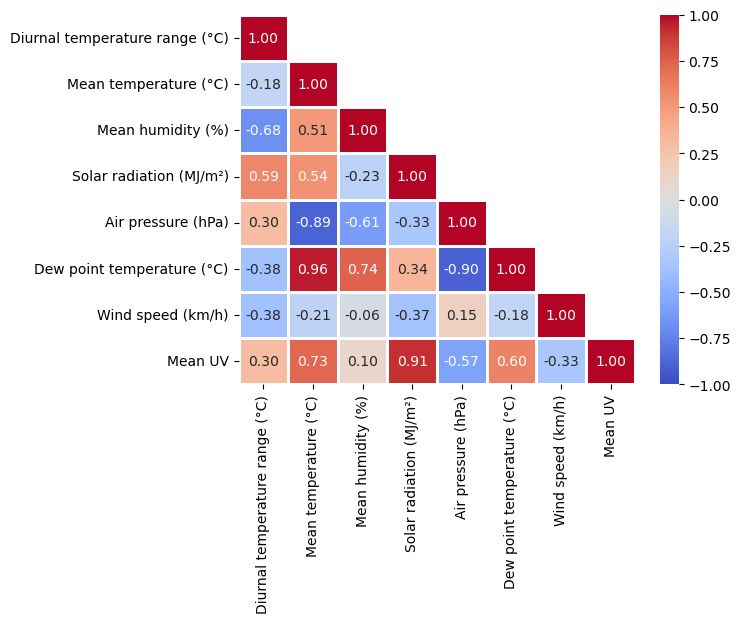

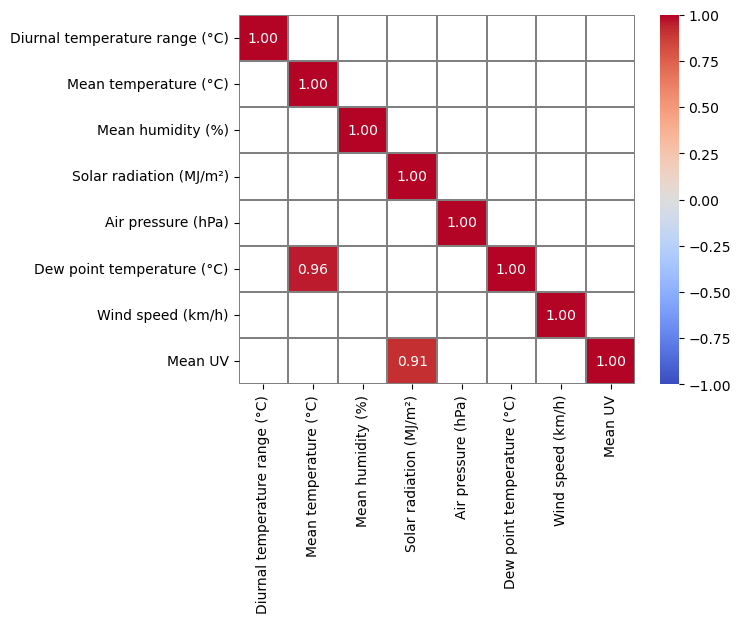

In [21]:
corr_weather = weather_df.drop(["Year", "Week", "From"], axis=1).corr()
display(corr_weather)

for i in range(0, 8):
    for j in range(i+1, 8):
        corr_weather.iloc[i, j] = np.nan

sns.heatmap(corr_weather, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f", linewidth=1)
plt.show()

for i in range(7, 0, -1):
    for j in range(i-1, -1, -1):
            if corr_weather.iloc[i, j] < 0.8:
                corr_weather.iloc[i, j] = np.nan


sns.heatmap(corr_weather, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f", linewidth=0.1, linecolor="gray")
plt.show()


In [22]:
plt.plot(temp_df["H1"])
plt.plot(temp_df["Mean temperature (°C)"], color="red")
plt.show()

NameError: name 'temp_df' is not defined

In [23]:
plt.scatter(temp_df["Mean temperature (°C)"], temp_df["H1"])

NameError: name 'temp_df' is not defined

---

In [ ]:
df

----
Test for linearity

In [ ]:
for val in df.columns[3:]:
    count = df[val].value_counts()
    if val in ["H1", "H3", "B", "AandB"]:
        count.index = [int(i) for i in count.index]
    count.drop(index=count[count.values == 1].index, inplace=True)
    plt.figure(figsize=(15, 4.8))
    count.plot(kind="bar")
    plt.xlabel(val)
    plt.ylabel("Counts")
    plt.show()

In [ ]:
for val in df.columns[3:]:
    stat = df[val].describe()
    stat = stat[["mean", "std"]]
    stat["var"] = stat["std"]**2
    stat.drop(index="std", inplace=True)
    print(stat)
    print("")

In [11]:
df = pd.read_csv("data.csv")

mete_col = ['Diurnal temperature range (°C)', 'Mean temperature (°C)', 'Mean humidity (%)', 'Solar radiation (MJ/m²)', 'Air pressure (hPa)', 'Dew point temperature (°C)', 'Wind speed (km/h)', 'Mean UV']
flu_col = ["H1", "H3", "B", "AandB"]
for i in mete_col:
    for j in flu_col:
        print(f"\nFor the columns {i} and {j}: ")
        
        # --- Fit a standard linear regression model ---
        X_with_const = sm.add_constant(df[i])
        linear_model = sm.OLS(df[j], X_with_const).fit()

        # ---- TEST 1: Ramsey RESET Test ----
        reset_test = linear_reset(linear_model, power=3, test_type='fitted')
        print("--- Ramsey RESET Test ---")
        print(reset_test.pvalue)

        if reset_test.pvalue < 0.05:
            print("Conclusion       : Non linear⚠️")
        else:
            print("Conclusion       : Linear ✅")
            
        # ---- TEST 2: BDS Test ----
        residuals = linear_model.resid
        bds_stat, bds_pvals = bds(residuals, max_dim=3)
        print("--- BDS Test (on residuals) ---")
        print(bds_pvals)
        
        
        def p_value_from_ci(lower, upper, confidence=0.95):
            alpha = 1 - confidence
            z_crit = stats.norm.ppf(1 - alpha / 2)
            estimate = (upper + lower) / 2
            se = (upper - lower) / (2 * z_crit)
            
            # Handle edge case where interval width is zero
            if se == 0:
                return 0.0 if estimate != 0 else 1.0
                
            # 4. Calculate the absolute Z-statistic
            z_stat = abs(estimate / se)
            
            # 5. Calculate the two-tailed p-value
            # stats.norm.sf(z) calculates 1 - Phi(z) directly and is more stable
            p_val = 2 * stats.norm.sf(z_stat)
            
            return p_val
        
        # --- Example Usage ---
        # Suppose your 95% Confidence Interval is [0.5, 2.5]
        lower_limit = 0.5
        upper_limit = 2.5
        
        p = p_value_from_ci(lower_limit, upper_limit, confidence=0.95)
        
        print("--- Derived Statistics ---")
        print(f"Derived p-value  : {p:.6f}")
        
        if p < 0.05:
            print("Conclusion       : Non linear⚠️")
        else:
            print("Conclusion       : Linear ✅")
        
        
 
        lm_stat, lm_p_val, f_stat, f_p_val = het_arch(residuals)
        print("--- ARCH-LM test ---")
        print(f"ARCH-LM p-value: {lm_p_val:.5f}")
        if p < 0.05:
            print("Conclusion       : Non linear⚠️")
        else:
            print("Conclusion       : Linear ✅")
        



For the columns Diurnal temperature range (°C) and H1: 
--- Ramsey RESET Test ---
0.3053492471612823
Conclusion       : Linear ✅
--- BDS Test (on residuals) ---
[2.84140968e-168 5.46126606e-154]
--- Derived Statistics ---
Derived p-value  : 0.003283
Conclusion       : Non linear⚠️
--- ARCH-LM test ---
ARCH-LM p-value: 0.00000
Conclusion       : Non linear⚠️

For the columns Diurnal temperature range (°C) and H3: 
--- Ramsey RESET Test ---
0.26648567580651067
Conclusion       : Linear ✅
--- BDS Test (on residuals) ---
[5.58805387e-203 3.25093065e-188]
--- Derived Statistics ---
Derived p-value  : 0.003283
Conclusion       : Non linear⚠️
--- ARCH-LM test ---
ARCH-LM p-value: 0.00000
Conclusion       : Non linear⚠️

For the columns Diurnal temperature range (°C) and B: 
--- Ramsey RESET Test ---
0.8083597357946359
Conclusion       : Linear ✅
--- BDS Test (on residuals) ---
[6.52477824e-165 1.73742507e-141]
--- Derived Statistics ---
Derived p-value  : 0.003283
Conclusion       : Non line

As all the results says that the relation are non-linear, we should avoid using linear models, instead use non-linear model